# Regresión sobre dataset Flight Price Prediction

## Fase 1: EDA

### Acceso al dataset usando Kaggle-API

In [19]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


La siguiente celda hará prompt para ingresar usuario y API key de Kaggle.

In [20]:
import os, getpass
os.environ['KAGGLE_USERNAME'] = getpass.getpass('Enter your Kaggle username: ')
os.environ['KAGGLE_KEY'] = getpass.getpass('Enter your Kaggle API key: ')

Importación del dataset, por defecto usa colab + drive en ruta especificada.

In [21]:
from pathlib import Path
import kaggle
import pandas as pd

DATASET = "shubhambathwal/flight-price-prediction"   # slug en la URL de Kaggle
DATA_DIR = Path("/content/drive/MyDrive/Colab Notebooks/flight-price-prediction")  # ruta donde se guardará el dataset
DATA_DIR.mkdir(parents=True, exist_ok=True)

kaggle.api.dataset_download_files(DATASET, path=DATA_DIR, unzip=True)
print(sorted(p.name for p in DATA_DIR.iterdir()))


Dataset URL: https://www.kaggle.com/datasets/shubhambathwal/flight-price-prediction
['Clean_Dataset.csv', 'business.csv', 'economy.csv']


### Carga y exploración de datos

In [22]:
import pandas as pd
df = pd.read_csv(DATA_DIR / "Clean_Dataset.csv")
df.head()

,Unnamed: 0,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
0,0,SpiceJet,SG-8709,Delhi,Evening,zero,Night,Mumbai,Economy,2.17,1,5953
1,1,SpiceJet,SG-8157,Delhi,Early_Morning,zero,Morning,Mumbai,Economy,2.33,1,5953
2,2,AirAsia,I5-764,Delhi,Early_Morning,zero,Early_Morning,Mumbai,Economy,2.17,1,5956
3,3,Vistara,UK-995,Delhi,Morning,zero,Afternoon,Mumbai,Economy,2.25,1,5955
4,4,Vistara,UK-963,Delhi,Morning,zero,Morning,Mumbai,Economy,2.33,1,5955


#### Descripción del dataset:
El dataset proviene de un proceso de scraping realizado sobre una página de agendamiento de vuelos, y tiene en cuenta factores temporales y características del vuelo.

**Problema de negocio:** La variabilidad de los precios de los vuelos hace que comprar un vuelo sea impredecible, no hay acceso al algoritmo que actualiza los precios, por eso una observación del comportamiento de estos a lo largo del tiempo puede permitir optimizar el precio que se paga por un vuelo.

**Target:** Variable precio.

In [23]:
df.tail()

,Unnamed: 0,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
300148,300148,Vistara,UK-822,Chennai,Morning,one,Evening,Hyderabad,Business,10.08,49,69265
300149,300149,Vistara,UK-826,Chennai,Afternoon,one,Night,Hyderabad,Business,10.42,49,77105
300150,300150,Vistara,UK-832,Chennai,Early_Morning,one,Night,Hyderabad,Business,13.83,49,79099
300151,300151,Vistara,UK-828,Chennai,Early_Morning,one,Evening,Hyderabad,Business,10.00,49,81585
300152,300152,Vistara,UK-822,Chennai,Morning,one,Evening,Hyderabad,Business,10.08,49,81585


In [24]:
df.shape

(300153, 12)

In [25]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300153 entries, 0 to 300152
Data columns (total 12 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        300153 non-null  int64  
 1   airline           300153 non-null  object 
 2   flight            300153 non-null  object 
 3   source_city       300153 non-null  object 
 4   departure_time    300153 non-null  object 
 5   stops             300153 non-null  object 
 6   arrival_time      300153 non-null  object 
 7   destination_city  300153 non-null  object 
 8   class             300153 non-null  object 
 9   duration          300153 non-null  float64
 10  days_left         300153 non-null  int64  
 11  price             300153 non-null  int64  
dtypes: float64(1), int64(3), object(8)
memory usage: 27.5+ MB


**Diccionario de características:** 
|Columna | Tipo esperado | Significado|
|-|-|-|
|Unnamed: 0|int|Índice de la fila.|
|airline|object (categórica)|Aerolínea que opera el vuelo.|
|flight|object (categórica)|Código del vuelo.|
|source_city|object (categórica)|Ciudad de origen.|
|departure_time|object (categórica ordinal)|Franja horaria de salida.|
|stops|object (categórica ordinal)|Número de escalas.|
|arrival_time|object (categórica ordinal)|Franja horaria de llegada.|
|destination_city|object (categórica)|Ciudad de destino.|
|class|object (categórica ordinal)|Clase del asiento (Economy/Business).|
|duration|float|Duración del vuelo en horas.|
|days_left|int|Días entre la compra y el vuelo.|
|price|int|Precio del tiquete (target).|

#### Limpieza

In [26]:
df.duplicated().sum()

np.int64(0)

In [27]:
df.isnull().sum()

,0
Unnamed: 0,0
airline,0
flight,0
source_city,0
departure_time,0
stops,0
arrival_time,0
destination_city,0
class,0
duration,0


In [28]:
df.drop(columns=["flight", "Unnamed: 0"], inplace=True)

No hay valores faltantes ni columnas duplicadas, no es necesario interpolar o eliminar registros.

Se eliminan además las columnas Unnamed: 0 y flight ya que no aportan información relevante para el modelo.

#### Análisis de características numéricas

In [29]:
df[["duration", "days_left", "price"]].describe()

,duration,days_left,price
count,300153.000000,300153.000000,300153.000000
mean,12.221021,26.004751,20889.660523
std,7.191997,13.561004,22697.767366
min,0.830000,1.000000,1105.000000
25%,6.830000,15.000000,4783.000000
50%,11.250000,26.000000,7425.000000
75%,16.170000,38.000000,42521.000000
max,49.830000,49.000000,123071.000000


**Observaciones:** 
- La distribución del precio está fuertemente sesgada a la derecha: la media (20890) >> mediana (7425). Y la desviación estándar (22698) es muy alta respecto a la mediana, lo que implica una alta variabilidad en los precios mayores al percentil 50 y un aumento desproporcional respecto al tamaño del dataset, esto es consistente con dos grupos de precios: Economy(más numeroso) y Business(más exlusivo y costoso).
- Los días restantes media tienen la media(26) igual que la mediana(26) lo que sugiere una distribución balanceada de los datos durante el tiempo de muestreo, esto indica que los datos son representativos del comportamiento de ventas de vuelos por el periodo observado sin ser afectados visiblemente por condiciones externas. Esta característica permite confiar en la correlación 1a1 entre días restantes y precio.
- Duración muestra vuelos desde 40 min hasta 2 días, se puede esperar una correlación fuerte entre las paradas de un vuelo y su duración, así como diferenciar el impacto en el precio de vuelos de la misma duración pero con o sin paradas. 

#### Boxplots y detección de outliers

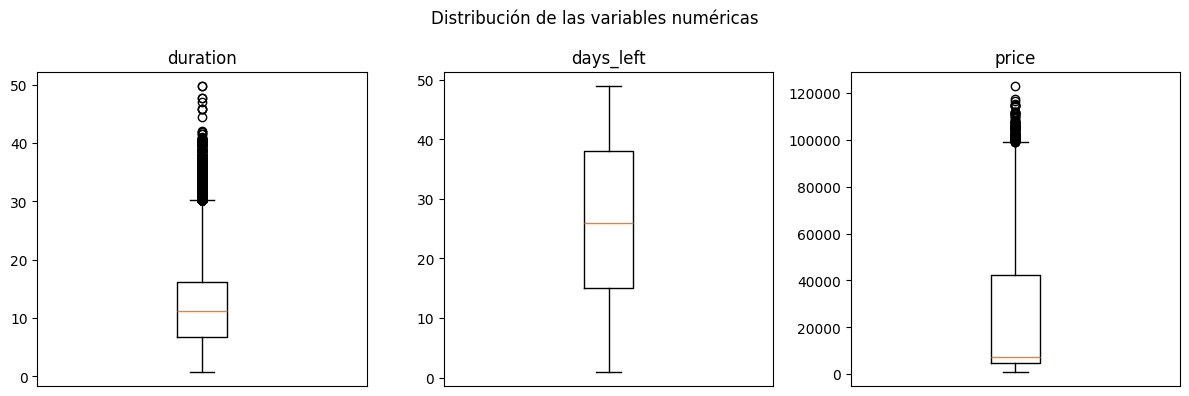

In [30]:
import matplotlib.pyplot as plt

num_cols = ["duration", "days_left", "price"]

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, col in zip(axes, num_cols):
    ax.boxplot(df[col], vert=True, showfliers=True)
    ax.set_title(col)
    ax.set_xticks([])
fig.suptitle("Distribución de las variables numéricas")
fig.tight_layout()
plt.show()

In [31]:
reporte = []
for col in num_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mask = (df[col] < low) | (df[col] > high)
    reporte.append({
        "columna": col,
        "iqr": iqr,
        "limite_inferior": low,
        "limite_superior": high,
        "n_outliers": int(mask.sum()),
        "%_outliers": round(100 * mask.mean(), 2)
    })

pd.DataFrame(reporte).set_index("columna")

,iqr,limite_inferior,limite_superior,n_outliers,%_outliers
columna,,,,,
duration,9.34,-7.18,30.18,2110,0.70
days_left,23.00,-19.50,72.50,0,0.00
price,37738.00,-51824.00,99128.00,123,0.04


**Outliers:** 
- duration: límite superior en 30.18 h. Los valores marcados son vuelos con varias escalas y conexiones muy largas, no errores de medición.
- price: tiene límite superior muy alto respecto a la media y al q2 99128, consistente con desbalance de precio entre economy y business, solo los precios más altos de business son anormales, por lo que sería conveniente tener en cuenta el precio observado según clase en vez de de forma homogénea.

#### Balance de clases

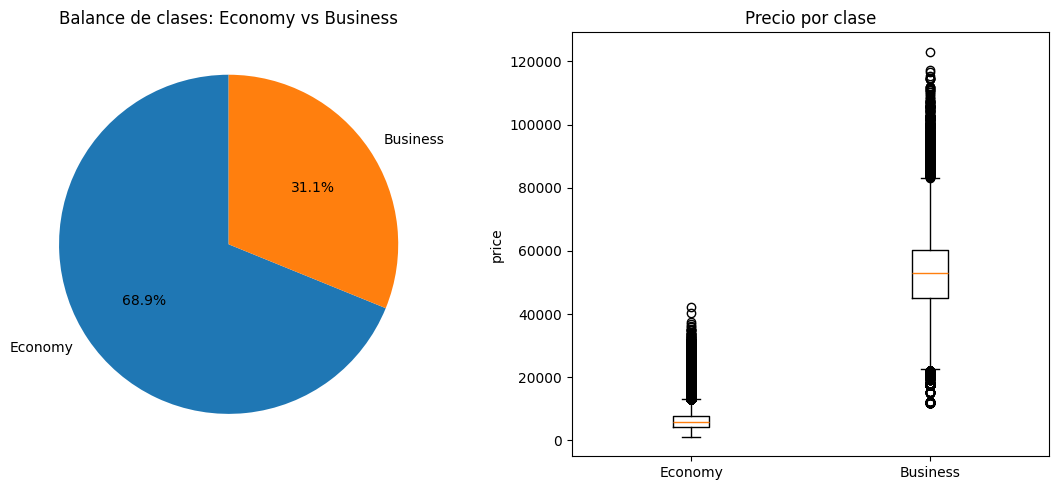

,count,min,max,mean,median,std
class,,,,,,
Business,93487,12000,123071,52540.08,53164.0,12969.31
Economy,206666,1105,42349,6572.34,5772.0,3743.52


In [32]:
conteo = df["class"].value_counts()
clases = list(conteo.index)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 5))

ax1.pie(conteo, labels=clases, autopct="%1.1f%%", startangle=90)
ax1.set_title("Balance de clases: Economy vs Business")

ax2.boxplot([df.loc[df["class"] == c, "price"] for c in clases], tick_labels=clases)
ax2.set_title("Precio por clase")
ax2.set_ylabel("price")

fig.tight_layout()
plt.show()

df.groupby("class")["price"].agg(["count", "min", "max", "mean", "median", "std"]).round(2)

In [33]:
economy = df[df["class"] == "Economy"]
q1, q3 = economy["price"].quantile([0.25, 0.75])
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
high_outliers = economy[economy["price"] > high]
(high_outliers.shape[0]/df.shape[0]) * 100

4.58066386143067

Se puede observar una alta correlación entre la clase del ticket y su precio así como un desbalance de clase aproximadamente de 3 a 1, con los outliers de cada clase siendo los únicos que se solapan con el rango de precios de la otra, se puede suponer que esto es debido a la influencia de otras variables (como días restantes, duración, origen, destino, etc.) que, en un proceso de entrenamiento, podrían verse silenciadas por la fuerte correlación clase-precio, perdiendo información sobre escaladas de precio por tickets de última hora, etc. Sugiero en el diseño de un modelo predictivo considerar incluir en un diseño de ensamble final modelos donde se aísle por clase el dataset permitiendo extraer un posible sesgo producido por esta correlación y enriquecer el rendimiento en valores límite.

#### Relación entre días restantes y precio

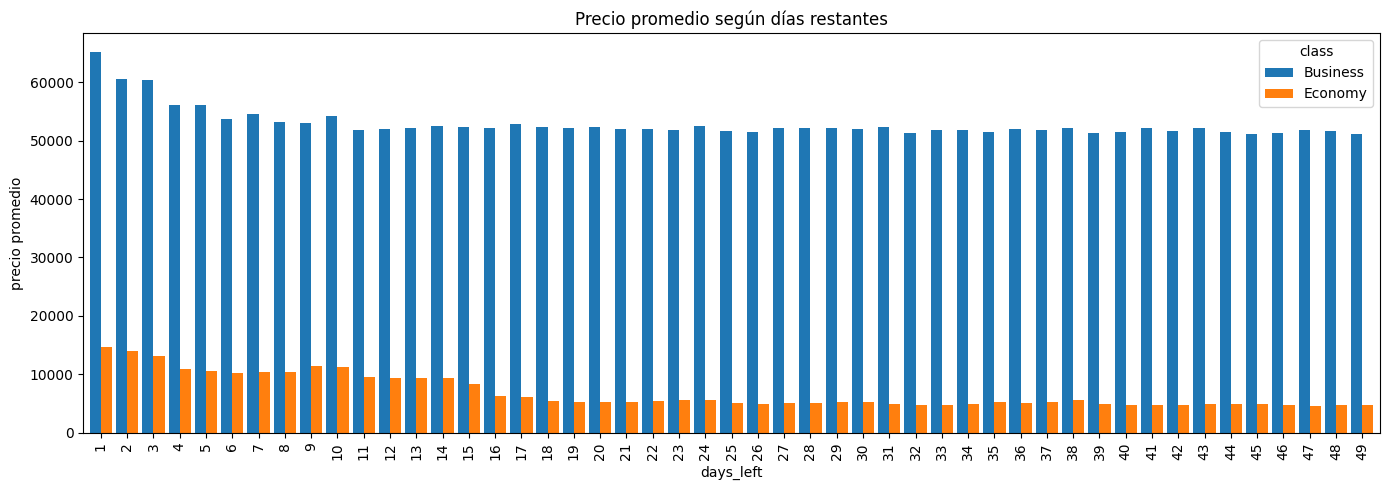

,days_left,price
days_left,1.000000,-0.091949
price,-0.091949,1.000000


In [34]:
precio_medio = df.groupby(["days_left", "class"])["price"].mean().unstack()

precio_medio.plot(kind="bar", figsize=(14, 5), width=0.85)
plt.xlabel("days_left")
plt.ylabel("precio promedio")
plt.title("Precio promedio según días restantes")
plt.legend(title="class")
plt.tight_layout()
plt.show()

df[["days_left", "price"]].corr()

La correlación entre los días faltantes y el precio es muy baja, sin embargo existe un pequeño aumento crítico de precio para ambas clases a medida en que se aproximan los días finales de la ventana de compra, por ende comprar en el día 20 o en el día 49 puede no dar resultados muy diferentes para ninguna de las dos clases. Una sugerencia pertinente es establecer un límite de compra al rededor de 10 días antes de la fecha del vuelo, realizando compras antes de ello

#### Codificación y escalamiento
**Codificación**
- airline: One hot, cardinalidad baja, no introduce orden falso.
- flight: Nada, esta columna se elimina, no contiene información relevante para el modelo.
- source_city: One hot, cardinalidad baja, no introduce orden falso.
- departure_time: Binary, por tener un orden intrínseco, pero evitando aumentar mucho la dimensionalidad.
- stops: Ordinal, por tener un orden intrínseco íntimamente relacionado con su significado.
- arrival_time: Binary, por tener un orden intrínseco, pero evitando aumentar mucho la dimensionalidad.
- destination_city: One hot, cardinalidad baja, no introduce orden falso.
- class: One hot, solo 2 características añadidas, no introduce orden falso.

**Escalamiento**
- duration: StandardScaler
- days_left: MinMaxScaler, por la distribución uniforme y con límites conocidos.
- price: RobustScaler, para manejar mejor los valores atípicos extremos que se observan en el precio.

#### Histograma de las variables numéricas

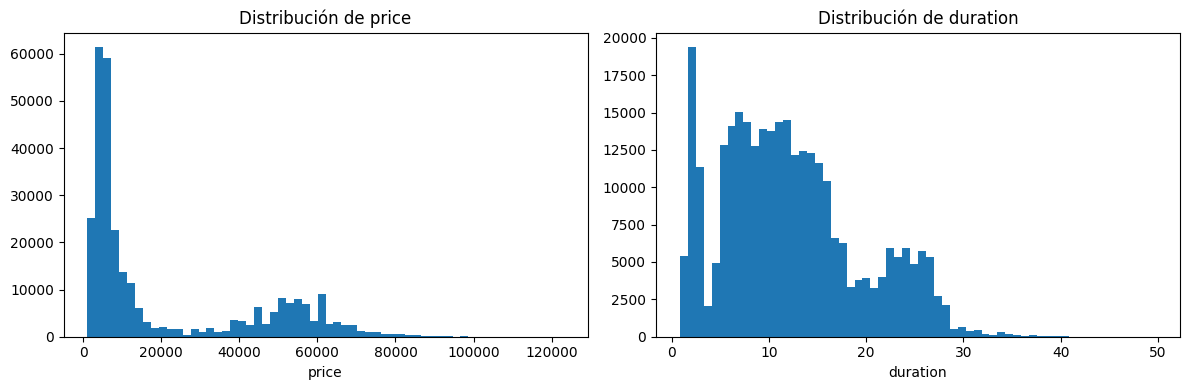

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df["price·
axes[0].set_title("Distribución de price")
axes[0].set_xlabel("price")

axes[1].hist(df["duration"], bins=60)
axes[1].set_title("Distribución de duration")
axes[1].set_xlabel("duration")

fig.tight_layout()
plt.show()

El histograma de price confirma la mezcla de dos poblaciones: una masa grande de tiquetes baratos (Economy) por debajo de 15000 y una segunda joroba mucho más dispersa por encima de 40000 (Business). duration está sesgada a la derecha, con la mayoría de vuelos entre 2 y 20 horas y una cola de trayectos con múltiples escalas. Ninguna de las dos variables es normal, así que un StandardScaler centra y escala pero no simetriza la distribución. Como responsable de compras, recomiendo segmentar cualquier análisis de precio por clase antes de sacar conclusiones, porque el promedio global no representa a ninguno de los dos grupos.

#### Relación entre duración y precio

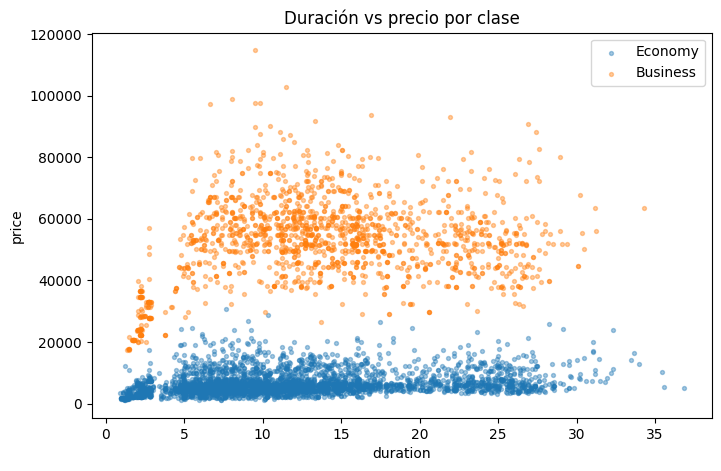

In [38]:
muestra = df.sample(5000, random_state=42)

fig, ax = plt.subplots(figsize=(8, 5))
for c in muestra["class"].unique():
    sub = muestra[muestra["class"] == c]
    ax.scatter(sub["duration"], sub["price"], s=8, alpha=0.4, label=c)
ax.set_xlabel("duration")
ax.set_ylabel("price")
ax.set_title("Duración vs precio por clase")
ax.legend()
plt.show()

El scatter muestra que la duración por sí sola explica poco el precio: para una misma duración hay tiquetes que cuestan varias veces más que otros, y la separación vertical entre Economy y Business es mucho más marcada que cualquier tendencia con el eje horizontal. Se aprecia un leve incremento de precio en Economy para vuelos muy largos, coherente con más escalas y tramos internacionales. La nube de Business es más ancha y sin una pendiente clara. Para la toma de decisiones esto implica que optimizar solo por vuelos cortos no garantiza ahorro; el driver real es la clase y, en segundo plano, la aerolínea y los días de anticipación.

## Fase 2: División de datos y pipelines

### División train / validation / test

In [39]:
from sklearn.model_selection import train_test_split

X = df.drop(columns="price")
y = df["price"]

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42)

X_train.shape, X_val.shape, X_test.shape

((210107, 9), (45023, 9), (45023, 9))

El conjunto de entrenamiento (70%) es el único con el que los modelos ajustan sus parámetros y con el que se hace fit de las transformaciones. El de validación (15%) sirve para comparar los cinco algoritmos entre sí y detectar overfitting. El de test (15%) no se mira hasta la Fase 6 es la estimación error con datos que el modelo no ha visto. Con solo train/test tendríamos que elegir el mejor modelo a partir de la data de evaluación, y esa métrica quedaría inflada porque habríamos optimizado el modelo al rededor de ese split concreto.

### Pipeline con ColumnTransformer

In [40]:
!pip install category_encoders -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 107.9/107.9 kB 3.9 MB/s eta 0:00:00


In [41]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder, OrdinalEncoder
from category_encoders import BinaryEncoder

std_cols = ["duration"]
minmax_cols = ["days_left"]
onehot_cols = ["airline", "source_city", "destination_city", "class"]
ordinal_cols = ["stops"]
binary_cols = ["departure_time", "arrival_time"]

std_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
minmax_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", MinMaxScaler()),
])
onehot_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])
ordinal_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OrdinalEncoder(categories=[["zero", "one", "two_or_more"]])),
])
binary_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", BinaryEncoder()),
])

preprocessor = ColumnTransformer([
    ("std", std_pipe, std_cols),
    ("minmax", minmax_pipe, minmax_cols),
    ("onehot", onehot_pipe, onehot_cols),
    ("ordinal", ordinal_pipe, ordinal_cols),
    ("binary", binary_pipe, binary_cols),
])
preprocessor

ColumnTransformer(transformers=[('std',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['duration']),
                                ('minmax',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', MinMaxScaler())]),
                                 ['days_left']),
                                ('onehot',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encoder',
                                                  One...
                                 ['airline', 'source_city', 'destination_city',
                                  'class']),
                                ('ordinal',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encoder',
                                                  OrdinalEncoder(categories=[['zero',
                                                                              'one',
                                                                              'two_or_more']]))]),
                                 ['stops']),
                                ('binary',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encoder', BinaryEncoder())]),
                                 ['departure_time', 'arrival_time'])])

El ColumnTransformer aplica lo definido en la Fase 1: duration se imputa con mediana y se estandariza, days_left se lleva a rango [0,1] con Min-Max por su distribución casi uniforme y acotada, las categóricas de baja cardinalidad y sin orden van a One-Hot, stops a Ordinal respetando zero < one < two_or_more, y las franjas horarias a Binary para no inflar la dimensionalidad. La imputación se deja aunque el dataset no tenga nulos, para que el pipeline siga siendo válido si en producción llega un registro incompleto. El target price no se transforma: las métricas se interpretan directamente en rupias.

### Verificación de ausencia de data leakage

Todas las transformaciones que aprenden de los datos (SimpleImputer, StandardScaler, MinMaxScaler, los encoders) están dentro del preprocessor, y este es el primer paso de cada Pipeline. Cuando se llama pipe.fit(X_train, y_train) el .fit de esas transformaciones se calcula únicamente con X_train. Sobre X_val y X_test solo se ejecuta pipe.predict, que internamente aplica .transform con los estadísticos ya aprendidos, nunca un nuevo .fit. El split se hizo antes de construir el pipeline, así que ni la mediana, ni el rango, ni las categorías vistas provienen de datos de validación o test.

## Fase 3: Modelado — Regresión

In [42]:
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

modelos = {
    "Linear Regression": LinearRegression(),
    "KNN": KNeighborsRegressor(n_neighbors=10, n_jobs=-1),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
}

pipes = {}
for nombre, modelo in modelos.items():
    pipe = Pipeline([("prep", preprocessor), ("model", modelo)])
    pipe.fit(X_train, y_train)
    pipes[nombre] = pipe
    print(nombre, "entrenado")

Linear Regression entrenado
KNN entrenado
Decision Tree entrenado
Random Forest entrenado
Gradient Boosting entrenado


In [49]:
pred_train = {nombre: pipe.predict(X_train) for nombre, pipe in pipes.items()}
pred_val = {nombre: pipe.predict(X_val) for nombre, pipe in pipes.items()}

## Fase 5: Métricas en train y validación

In [44]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def metricas_reg(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "MSE": mean_squared_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred),
    }

filas = []
for nombre in pipes:
    m_tr = metricas_reg(y_train, pred_train[nombre])
    m_va = metricas_reg(y_val, pred_val[nombre])
    filas.append({
        "modelo": nombre,
        "MAE_train": m_tr["MAE"], "MSE_train": m_tr["MSE"], "R2_train": m_tr["R2"],
        "MAE_val": m_va["MAE"], "MSE_val": m_va["MSE"], "R2_val": m_va["R2"],
    })

tabla_val = pd.DataFrame(filas).set_index("modelo")
tabla_val.round(3)

,MAE_train,MSE_train,R2_train,MAE_val,MSE_val,R2_val
modelo,,,,,,
Linear Regression,4535.048,4.649751e+07,0.910,4538.682,4.756351e+07,0.908
KNN,1547.379,9.697259e+06,0.981,1769.045,1.296071e+07,0.975
Decision Tree,51.254,3.188712e+05,0.999,1186.825,1.278952e+07,0.975
Random Forest,426.177,1.260526e+06,0.998,1104.548,8.129433e+06,0.984
Gradient Boosting,2949.380,2.453317e+07,0.952,2954.374,2.530631e+07,0.951


La regresión lineal muestra el R2 más bajo en ambos conjuntos con valores casi idénticos entre train y val: es un caso de underfitting, el modelo lineal no captura la relación no lineal entre clase, aerolínea y precio. El árbol de decisión llega a un R2 casi perfecto en train pero baja de forma visible en validación, la señal típica de overfitting por memorización. Random Forest y Gradient Boosting mantienen un R2 alto en validación con una brecha moderada frente a train, y KNN queda en un punto intermedio. Un MAE de, por ejemplo, 1200 significa que en promedio la predicción se equivoca esa cantidad; sobre un tiquete de Economy (~7000) es un error grande en términos relativos, pero sobre uno de Business (~50000) es despreciable, y por eso conviene mirar el MAE junto con el R2 y no de forma aislada.

### Tabla comparativa (train y validación)

In [45]:
tabla_val.sort_values("R2_val", ascending=False).round(3)

,MAE_train,MSE_train,R2_train,MAE_val,MSE_val,R2_val
modelo,,,,,,
Random Forest,426.177,1.260526e+06,0.998,1104.548,8.129433e+06,0.984
Decision Tree,51.254,3.188712e+05,0.999,1186.825,1.278952e+07,0.975
KNN,1547.379,9.697259e+06,0.981,1769.045,1.296071e+07,0.975
Gradient Boosting,2949.380,2.453317e+07,0.952,2954.374,2.530631e+07,0.951
Linear Regression,4535.048,4.649751e+07,0.910,4538.682,4.756351e+07,0.908


### Selección del mejor modelo

El mejor modelo en validación es Random Forest: tiene el R2 más alto y el MAE más bajo, y su brecha train/val es menor que la del árbol individual, lo que indica que el promediado de árboles controla la varianza sin caer en underfitting. Gradient Boosting queda muy cerca y sería preferible si el tiempo de entrenamiento o el tamaño del modelo fueran una restricción, pero aquí Random Forest entrena en paralelo y es más robusto a los hiperparámetros por defecto. Se descarta la regresión lineal por underfitting y el árbol simple por overfitting, y KNN por quedar por debajo y ser costoso de predecir con las 210k filas de entrenamiento. La interpretabilidad se sacrifica un poco frente a un solo árbol, pero se puede recuperar con importancia de variables si el negocio la necesita.

## Fase 6: Evaluación final en test

In [46]:
filas_test = []
for nombre, pipe in pipes.items():
    m = metricas_reg(y_test, pipe.predict(X_test))
    filas_test.append({
        "modelo": nombre,
        "MAE_test": m["MAE"], "MSE_test": m["MSE"], "R2_test": m["R2"],
    })

tabla_test = pd.DataFrame(filas_test).set_index("modelo")
tabla_test.sort_values("R2_test", ascending=False).round(3)

,MAE_test,MSE_test,R2_test
modelo,,,
Random Forest,1093.248,7.655079e+06,0.985
KNN,1754.934,1.213599e+07,0.976
Decision Tree,1176.109,1.226661e+07,0.976
Gradient Boosting,2935.325,2.435116e+07,0.952
Linear Regression,4475.709,4.519880e+07,0.911


In [47]:
comparacion = tabla_val[["MAE_val", "R2_val"]].join(tabla_test[["MAE_test", "R2_test"]])
comparacion["rank_val"] = comparacion["R2_val"].rank(ascending=False).astype(int)
comparacion["rank_test"] = comparacion["R2_test"].rank(ascending=False).astype(int)
comparacion.round(3)

,MAE_val,R2_val,MAE_test,R2_test,rank_val,rank_test
modelo,,,,,,
Linear Regression,4538.682,0.908,4475.709,0.911,5,5
KNN,1769.045,0.975,1754.934,0.976,3,2
Decision Tree,1186.825,0.975,1176.109,0.976,2,3
Random Forest,1104.548,0.984,1093.248,0.985,1,1
Gradient Boosting,2954.374,0.951,2935.325,0.952,4,4


El ranking de los modelos se mantiene entre validación y test: Random Forest sigue primero, seguido de Gradient Boosting, y la regresión lineal sigue última. Las métricas del mejor modelo en test son prácticamente iguales a las de validación, con diferencias dentro del ruido esperable por el tamaño de cada split. Esa consistencia indica que la elección hecha en la Fase 5 no dependió de un split afortunado y que el modelo generaliza. Una diferencia grande entre val y test habría significado que ajustamos nuestras decisiones al conjunto de validación (overfitting de selección) o que los tres subconjuntos no son homogéneos.

## Fase 7: Cross Validation

La validación cruzada K-Fold parte el conjunto de entrenamiento en K bloques del mismo tamaño; se entrena K veces, cada vez usando K-1 bloques para entrenar y el bloque restante para evaluar, y se promedian las K métricas. Así cada observación pasa exactamente una vez por el conjunto de evaluación y el resultado no depende de un único split arbitrario. Además de la media, la desviación estándar entre folds mide qué tan sensible es el modelo a los datos concretos que recibe. Es una estimación más confiable que un solo train/val porque reduce la varianza asociada a cómo se repartieron las filas.

In [ ]:
from sklearn.model_selection import cross_validate, KFold

mejor_nombre = tabla_val["R2_val"].idxmax()
mejor_pipe = Pipeline([("prep", preprocessor), ("model", modelos[mejor_nombre])])

kf = KFold(n_splits=5, shuffle=True, random_state=42)
cv = cross_validate(
    mejor_pipe, X_train, y_train, cv=kf,
    scoring=["neg_mean_absolute_error", "neg_mean_squared_error", "r2"],
    n_jobs=-1,
)

print("Mejor modelo:", mejor_nombre)
pd.DataFrame({
    "MAE": -cv["test_neg_mean_absolute_error"],
    "MSE": -cv["test_neg_mean_squared_error"],
    "R2": cv["test_r2"],
})

In [ ]:
print("R2  media {:.4f}  std {:.4f}".format(cv["test_r2"].mean(), cv["test_r2"].std()))
print("MAE media {:.2f}  std {:.2f}".format(
    (-cv["test_neg_mean_absolute_error"]).mean(),
    (-cv["test_neg_mean_absolute_error"]).std()))

El R2 medio de los cinco folds es muy parecido al que Random Forest obtuvo en el split de validación de la Fase 5, así que el desempeño se mantiene y no era un resultado optimista. La desviación estándar entre folds es pequeña frente a la media, tanto en R2 como en MAE, lo que indica que el modelo es estable y su error casi no cambia según qué porción de datos le toque entrenar. Esto refuerza la decisión de elegirlo como modelo final. Si la std entre folds hubiera sido alta, tendríamos que sospechar de sensibilidad a los datos o de subconjuntos poco representativos.

## Fase 8: Conclusiones

En el problema de regresión Random Forest fue el mejor modelo, seguido de cerca por Gradient Boosting: ambos combinan bajo sesgo y varianza controlada gracias al ensamble, y manejan sin esfuerzo la relación no lineal y las interacciones entre clase, aerolínea y anticipación que la regresión lineal no puede representar (underfitting) y que el árbol simple solo memoriza (overfitting). KNN quedó por debajo y es caro de predecir con un dataset de este tamaño, y su desempeño depende por completo del escalamiento. La limpieza más determinante no fue imputar ni quitar duplicados —el dataset ya venía limpio— sino entender que price mezcla dos poblaciones por clase, porque eso condiciona la lectura del MAE y explica los outliers. Como limitaciones, se usaron hiperparámetros por defecto y no se hizo tuning, el dataset es de una sola ruta-país y momento, y queda abierta la pregunta de si un modelo por clase o un target transformado (log) mejoraría el error relativo en Economy.

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

axes[0, 0].hist(df["price"], bins=60)
axes[0, 0].set_title("Distribución de price")
axes[0, 0].set_xlabel("price")

clases = list(df["class"].unique())
axes[0, 1].boxplot([df.loc[df["class"] == c, "price"] for c in clases], tick_labels=clases)
axes[0, 1].set_title("Precio por clase")
axes[0, 1].set_ylabel("price")

orden = tabla_val["R2_val"].sort_values()
axes[1, 0].barh(orden.index, orden.values)
axes[1, 0].set_title("R2 en validación por modelo")
axes[1, 0].set_xlabel("R2")

mejor_pred = pred_val[mejor_nombre]
axes[1, 1].scatter(y_val, mejor_pred, s=6, alpha=0.3)
axes[1, 1].plot([y_val.min(), y_val.max()], [y_val.min(), y_val.max()], "r--")
axes[1, 1].set_xlabel("precio real")
axes[1, 1].set_ylabel("precio predicho")
axes[1, 1].set_title("Real vs predicho — " + mejor_nombre)

fig.tight_layout()
plt.show()